In [1]:
pip install pandas numpy matplotlib seaborn statsmodels openpyxl

Note: you may need to restart the kernel to use updated packages.


In [15]:
pip install --upgrade openpyxl


  Obtaining dependency information for openpyxl from https://files.pythonhosted.org/packages/c0/da/977ded879c29cbd04de313843e76868e6e13408a94ed6b987245dc7c8506/openpyxl-3.1.5-py2.py3-none-any.whl.metadata
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.9/250.9 kB 6.0 MB/s eta 0:00:0000:01
  Attempting uninstall: openpyxl
    Found existing installation: openpyxl 3.0.10
    Uninstalling openpyxl-3.0.10:
      Successfully uninstalled openpyxl-3.0.10
Note: you may need to restart the kernel to use updated packages.


In [15]:

import pandas as pd

#Load your downloaded files
path="/Users/pranjaligupta/Desktop/FF/Thailand-Financial-Research/02_Data/processed/FinalData.csv"
data=pd.read_csv(path)

In [21]:
data.columns=['date','us_10y','debt_gdp','thai_10y']

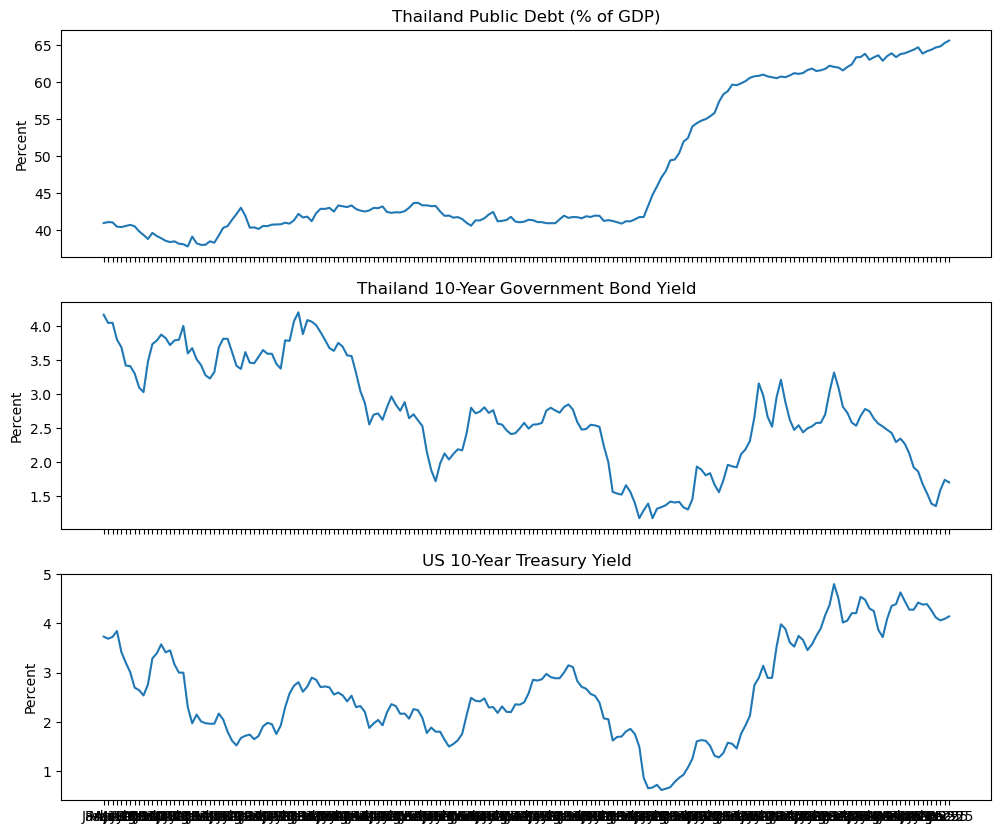

In [28]:
import matplotlib.pyplot as plt

df = pd.read_csv(path)
df.columns=['date','us_10y','debt_gdp','thai_10y']
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(df["date"], df["debt_gdp"])
axes[0].set_title("Thailand Public Debt (% of GDP)")
axes[0].set_ylabel("Percent")

axes[1].plot(df["date"], df["thai_10y"])
axes[1].set_title("Thailand 10-Year Government Bond Yield")
axes[1].set_ylabel("Percent")

axes[2].plot(df["date"], df["us_10y"])
axes[2].set_title("US 10-Year Treasury Yield")
axes[2].set_ylabel("Percent")

# plt.tight_layout()
# plt.savefig("outputs/charts/series_over_time.png", dpi=300)
plt.show()


In [29]:
print(df.isna().sum())
print(df.duplicated(subset="date").sum())
print(df.tail())

date        0
us_10y      0
debt_gdp    0
thai_10y    0
dtype: int64
0
       date    us_10y  debt_gdp  thai_10y
187  Aug-25  4.264762     64.41  1.387259
188  Sep-25  4.120476     64.71  1.349770
189  Oct-25  4.061818     64.85  1.584436
190  Nov-25  4.093889     65.31  1.736950
191  Dec-25  4.143182     65.64  1.700018


In [39]:
pip install pandas plotly

Note: you may need to restart the kernel to use updated packages.


In [40]:
import plotly.graph_objects as go
import pandas as pd

In [42]:
df.columns

Index(['Dates', 'US 10Y Treasury', 'Thai Debt:GDP ', 'Thai 10Y Treasury'], dtype='str')

In [46]:
pwd

'/Users/pranjaligupta/Desktop/FF/Thailand-Financial-Research/03_Analysis/notebooks'

In [65]:

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ==========================================
# 1. LOAD AND PREPARE DATA
# ==========================================

df = pd.read_csv(path)

# Convert dates
df["Dates"] = pd.to_datetime(df["Dates"], format="%b-%y")

# Sort chronologically
df = df.sort_values("Dates")

# ==========================================
# 2. 10-YEAR GOVERNMENT BOND YIELDS
# ==========================================
covid_start = "2020-03-01"
covid_end = "2021-12-31"
fig1 = go.Figure()

# US 10-Year Treasury
fig1.add_trace(go.Scatter(
    x=df["Dates"],
    y=df["US 10Y Treasury"],
    mode="lines",
    name="United States",
    line=dict(color="#1f77b4", width=2.5)
))

# Thailand 10-Year Treasury
fig1.add_trace(go.Scatter(
    x=df["Dates"],
    y=df["Thai 10Y Treasury"],
    mode="lines",
    name="Thailand",
    line=dict(color="#e67e22", width=2.5)
))

fig1.update_layout(
    title=dict(
        text="US vs Thailand 10-Year Government Bond Yields",
        x=0.5,
        font_family='Georgia',
        font_size=20
    ),
    xaxis_title="Date",
    yaxis_title="Yield (%)",
    template="plotly_white",
    hovermode="x unified",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5
    ),
    height=600,
    margin=dict(l=60, r=40, t=100, b=60)
)

fig1.update_xaxes(
    showgrid=True,
    gridcolor="rgba(128,128,128,0.15)"
)

fig1.update_yaxes(
    showgrid=True,
    gridcolor="rgba(128,128,128,0.15)",
    ticksuffix="%"
)

fig1.add_vrect(
    x0=covid_start,
    x1=covid_end,
    fillcolor="red",
    opacity=0.05,
    layer="below",
    line_width=0,
    annotation_text="COVID-19",
    annotation_position="top left",
    annotation_font_family="Georgia",
    annotation_font_size=12
)

fig1.show()

# ==========================================
# 3. THAILAND DEBT-TO-GDP
# ==========================================

fig2 = go.Figure()

fig2.add_trace(go.Scatter(
    x=df["Dates"],
    y=df["Thai Debt:GDP "],
    mode="lines",
    name="Thailand Debt-to-GDP",
    line=dict(color="#16a085", width=2.5),
    fill="tozeroy",
    fillcolor="rgba(22,160,133,0.10)"
))

fig2.update_layout(
    title=dict(
        text="Thailand Government Debt-to-GDP",
        font_size= 20,
        font_family='Georgia',
        x=0.5
    ),
    xaxis_title="Date",
    yaxis_title="Debt-to-GDP (%)",
    template="plotly_white",
    hovermode="x unified",
    height=600,
    showlegend=False,
    margin=dict(l=60, r=40, t=100, b=60)
)

fig2.update_xaxes(
    showgrid=True,
    gridcolor="rgba(128,128,128,0.15)"
)

fig2.update_yaxes(
    showgrid=True,
    gridcolor="rgba(128,128,128,0.15)",
    ticksuffix="%"
)

fig2.add_vrect(
    x0=covid_start,
    x1=covid_end,
    fillcolor="red",
    opacity=0.05,
    layer="below",
    line_width=0,
    annotation_text="COVID-19",
    annotation_position="top left",
    annotation_font_family="Georgia",
    annotation_font_size=12
)

fig2.show()

# ==========================================
# 4. EXPORT INTERACTIVE HTML FILES
# ==========================================

fig1.write_html("/Users/pranjaligupta/Desktop/FF/Thailand-Financial-Research/03_Analysis/charts/Treasury_Yields.html")
fig2.write_html("/Users/pranjaligupta/Desktop/FF/Thailand-Financial-Research/03_Analysis/charts/Thailand_Debt_GDP.html")

print("Charts successfully generated!")


Charts successfully generated!
